In [20]:
# Importing Necessary Libraries

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [21]:
    # Load the Breast Cancer Wisconsin Dataset

df = pd.read_csv("/home/aditya/Downloads/data.csv")

print("Dataset loaded successfully")
print(df.head())
print("\nDataset Shape:", df.shape)

Dataset loaded successfully
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_w

In [22]:
# Prepare Input and Output Data

X = df.drop(
    columns=['id', 'diagnosis', 'Unnamed: 32'],
    errors='ignore'
)

y = df['diagnosis'].map({'M': 1, 'B': 0})

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)
print("Data prepared successfully")

Input Shape: (569, 30)
Output Shape: (569,)
Data prepared successfully


In [23]:
# Split Dataset into Training and Testing Sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)


In [24]:
# Normalize Input Data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data normalization completed successfully")# Normalize Input Data



Data normalization completed successfully


In [25]:
# Reshape Data for CNN

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (455, 30, 1)
Testing Data Shape: (114, 30, 1)


In [26]:
# Create Convolutional Neural Network

model = tf.keras.Sequential([
    tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=3,
        activation='relu',
        input_shape=(X_train.shape[1], 1)
    ),
    tf.keras.layers.MaxPooling1D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

print("CNN model created successfully")

CNN model created successfully


/home/aditya/AIDS_EXP/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
# Compile the CNN Model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully")

CNN model compiled successfully


In [28]:
# Train the CNN Model

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

print("CNN model training completed successfully")

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8434 - loss: 0.4699 - val_accuracy: 0.9231 - val_loss: 0.3028
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9423 - loss: 0.2282 - val_accuracy: 0.9341 - val_loss: 0.1887
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9505 - loss: 0.1411 - val_accuracy: 0.9341 - val_loss: 0.1575
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9725 - loss: 0.1063 - val_accuracy: 0.9560 - val_loss: 0.1388
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9698 - loss: 0.0889 - val_accuracy: 0.9451 - val_loss: 0.1312
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9753 - loss: 0.0797 - val_accuracy: 0.9560 - val_loss: 0.1223
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9808 - loss: 0.0718 - val_accuracy: 0.9451 - val_loss: 0.1238
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9808 - loss: 0.0681 - val_accuracy: 0.9560 - val_loss

In [29]:
# Evaluate the CNN Model

loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

Test Loss: 0.052497219294309616
Test Accuracy: 0.9824561476707458
Test Accuracy (%): 98.24561476707458


In [30]:
# Make Predictions using CNN

y_pred_probability = model.predict(X_test)

y_pred = (y_pred_probability > 0.5).astype(int)

print("Predictions generated successfully")
print("First 10 Predictions:")
print(y_pred[:10].flatten())

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Predictions generated successfully
First 10 Predictions:
[0 1 0 1 0 0 1 0 0 0]


In [31]:
# Compare Actual and Predicted Values

comparison = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': y_pred.flatten()
})

print(comparison.head(10))

   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          0
5       0          0
6       1          1
7       0          0
8       0          0
9       0          0


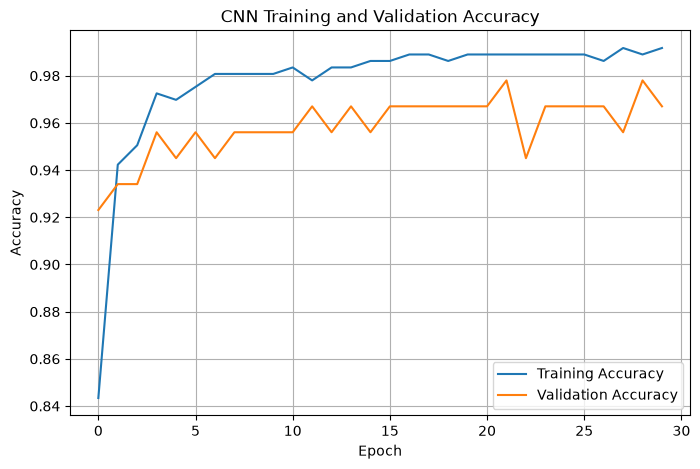

In [32]:
# Plot CNN Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Training and Validation Accuracy')
plt.legend()
plt.grid(True)

plt.show()

In [33]:
# Display Final CNN Performance

print("CNN Model Performance")
print("---------------------")
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

CNN Model Performance
---------------------
Test Loss: 0.052497219294309616
Test Accuracy: 0.9824561476707458
Test Accuracy (%): 98.24561476707458
